In [1]:
import scanpy as sc
import sys
import os

sys.path.append("../../analyses/utils/HECA/")
import data_cleanup
import mapping

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:lightning_fabric.utilities.seed:[rank: 0] Global seed set to 0
 captum (see https://github.com/pytorch/captum).


In [2]:
# %load_ext lab_black
%load_ext autoreload
%autoreload 2

In [3]:
testrun = False

In [4]:
batch_covariate = "sample"
kl = 1

In [5]:
suffix = ""
if testrun:
    suffix = "_test"
path_reference = "../../../../../workspace/lisa.sikkema/mapqc/data/HECA/reference/endometriumAtlasV2_cells_with_counts.h5ad"
path_query = "../../../../../workspace/lisa.sikkema/mapqc/data/HECA/queries_counts/Asherman_syndrome_wo_wang.h5ad"
path_ref_model_dir = "./scanvi_ref_model/"
path_surgery_model_dir = (
    f"../../results/HECA/batch_{batch_covariate}_kl{kl}/surgery_model_and_output_emb"
)
path_to_mapped_query_embedding = os.path.join(
    path_surgery_model_dir, f"query_emb{suffix}.h5ad"
)
path_to_joint_ref_q_counts_object = f"/lustre/groups/ml01/workspace/lisa.sikkema/mapqc/data/HECA/HECA_Santamaria{suffix}.h5ad"
path_to_joint_ref_q_latent_object = f"/lustre/groups/ml01/workspace/lisa.sikkema/mapqc/data/HECA/HECA_Santamaria_batch_{batch_covariate}_kl{kl}_latent{suffix}.h5ad"

In [6]:
adata_ref = data_cleanup.import_and_prepare_reference(path_reference, testrun=testrun)

Removing disease data from reference.


In [7]:
adata_q = data_cleanup.import_and_prepare_query(path_query, testrun=testrun)

In [8]:
adata_q.obs.Group.value_counts()

AS             40336
WOI Control    18965
Name: Group, dtype: int64

In [9]:
adata_q = mapping.prepare_query_data_for_mapping(adata_q, batch_key="sample")

In [16]:
(
    adata_ref_latent,
    adata_q_subset,
) = mapping.subset_query_data_for_mapping_and_get_ref_latent(
    adata_ref=adata_ref, adata_q=adata_q, path_to_ref_model_dir=path_ref_model_dir
)

This function still needs to be tested.
INFO     File ./scanvi_ref_model/model.pt already downloaded                                                       


/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scvi/data/_utils.py:175: UserWarning: Category 19 in adata.obs['_scvi_labels'] has fewer than 3 cells. Models may not train properly.
  warnings.warn(
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scvi/data/_utils.py:175: UserWarning: Category 19 in adata.obs['_scvi_labels'] has fewer than 3 cells. Models may not train properly.
  warnings.warn(


INFO     File ./scanvi_ref_model/model.pt already downloaded                                                       
INFO     Found 100.0% reference vars in query data.                                                                


In [17]:
mapping.map_data_to_HECA_reference(
    prepped_query_adata=adata_q_subset,
    path_ref_model_dir=path_ref_model_dir,
    path_surgery_model_dir=path_surgery_model_dir,
    path_output_query_emb=path_to_mapped_query_embedding,
    testrun=testrun,
)

INFO     File ./scanvi_ref_model/model.pt already downloaded                                                       
INFO     Training for 500 epochs.                                                                                  


/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/lightning_fabric/plugins/environments/slurm.py:166: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_ ...
  rank_zero_warn(
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/lightning_fabric/plugins/environments/slurm.py:166: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Li

Epoch 500/500: 100%|██████████| 500/500 [57:50<00:00,  6.95s/it, loss=855, v_num=1]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=500` reached.


Epoch 500/500: 100%|██████████| 500/500 [57:50<00:00,  6.94s/it, loss=855, v_num=1]
Saving surgery model to ../../results/HECA/batch_sample_kl1/surgery_model_and_output_emb...
Saving mapped query embedding to ../../results/HECA/batch_sample_kl1/surgery_model_and_output_emb/query_emb.h5ad...


In [18]:
adata_ref_latent

AnnData object with n_obs × n_vars = 168434 × 10
    obs: 'celltype'

In [19]:
adata_emb = mapping.create_and_save_mapping_output_adata(
    adata_reference=adata_ref,
    adata_reference_latent=adata_ref_latent,
    adata_query=adata_q,
    path_to_mapped_query_emb=path_to_mapped_query_embedding,
    output_path_joint_emb=path_to_joint_ref_q_latent_object,
    add_umap=True,
    add_leiden=True,
    perform_label_transfer=True,
    k=30,
    verbose=True,
)

Performing label transfer using the reference and query latent representations...
Using .X of reference data
Using .X of query data
Predicting labels for celltype
Calculating KNN graph...
Calculating UMAP (this might take a while!)...
Calculating Leiden clustering...
Saving joint embedding to /lustre/groups/ml01/workspace/lisa.sikkema/mapqc/data/HECA/HLCA_Santamaria_batch_sample_kl1_latent.h5ad...


In [16]:
if not os.path.isfile(path_to_joint_ref_q_counts_object):
    print(
        f"Creating joint counts object and writing to {path_to_joint_ref_q_counts_object}..."
    )
    adata_counts = mapping.create_joint_ref_q_counts_object(adata_ref, adata_q)
    adata_counts.write(path_to_joint_ref_q_counts_object)
else:
    print(
        "Not creating joint counts object, as it has already been created in a previous run."
    )

Creating joint counts object and writing to /lustre/groups/ml01/workspace/lisa.sikkema/mapqc/data/HECA/HECA_Santamaria.h5ad...
Concatenating reference and query data...


In [21]:
adata = data_cleanup.add_mapping_info_to_counts_adata(
    adata_counts, adata_emb, celltype_col="celltype"
)

In [22]:
adata

AnnData object with n_obs × n_vars = 227735 × 29989
    obs: 'n_genes', 'sample', 'library', 'Processing', 'Treatment', '10x kit', 'percent_mito', 'n_counts', 'scrublet_score', 'genotype', 'Library_genotype', 'Group', 'Endometriosis_stage', 'Hormonal treatment', 'Binary Stage', 'Stage', 'phase', 'dataset', 'Biopsy_type', 'Tissue_sampled', 'Age', 'Endometrial_pathology', 'celltype', 'lineage', 'label_long', 'r_or_q', 'nFeature_RNA', 'menstrual_cycle_day', 'principal_celltype_query', 'celltype_query', 'batch_variable_for_mapping', 'celltype_pred', 'celltype_prob', 'leiden', 'celltype_merged'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'features'
    obsm: 'X_umap', 'X_scanvi_emb'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/HLCA_mapping_env_new/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


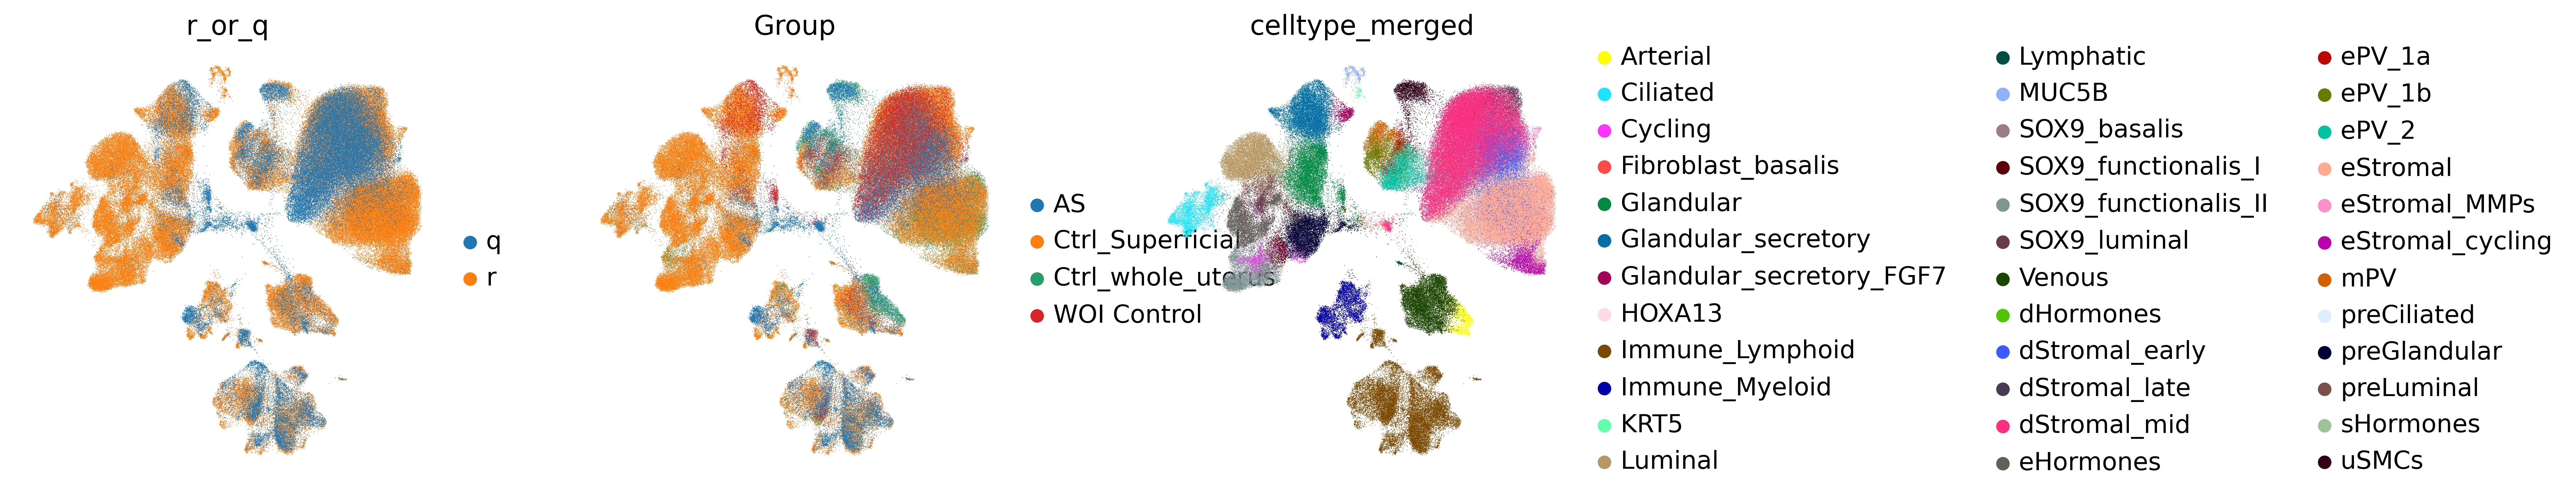

In [25]:
sc.pl.umap(adata, color=["r_or_q", "Group", "celltype_merged"], ncols=3, frameon=False)